# LLM-generated cell ontology comparison

Analysis of the biological dimension ontologies generated by different LLMs
(see `src/00_llm_ontologies.py`) at latent sizes 16, 32 and 48. We compare the
ontology term IDs (KEGG/Reactome/GO) assigned to each model's dimensions, both
directly and via LLM-based dimension matching (`src/compare_stripped_ontologies.py`),
to assess overlap and consistency across models and latent sizes.

In [2]:
import os
import json
import glob

all_ontologies = {}

ontology_dir = "../data/llm_ontologies/output_llms/"
for filepath in glob.glob(os.path.join(ontology_dir, "*_ontology.json")):
	filename = os.path.basename(filepath)
	key = filename[:-len("_ontology.json")]
	with open(filepath, "r", encoding="utf-8") as f:
		ontology = json.load(f)
	all_ontologies[key] = ontology

print(f"Loaded {len(all_ontologies)} ontologies: {list(all_ontologies.keys())}")

Loaded 9 ontologies: ['Dim48_KimiK3', 'Dim32_GPT5.6_TerraPro', 'Dim48_ClaudeOpus5', 'Dim48_GPT5.6_TerraPro', 'Dim16_KimiK3', 'Dim32_ClaudeOpus5', 'Dim16_GPT5.6_TerraPro', 'Dim16_ClaudeOpus5', 'Dim32_KimiK3']


## Term ID extraction

Flatten each ontology to the set of database term IDs assigned to its dimensions,
ignoring dimension boundaries, for use in the model-level comparisons below.

In [ ]:
# For each ont_key, collect all term "id"s across all dim_name entries
ontology_ids = {}
for key, ontology in all_ontologies.items():
	terms = ontology[f"{key}_ontology"]
	ids = [
		term["id"]
		for dim_name in terms
		for term in terms[dim_name]["ontology_terms"]
	]
	ontology_ids[key] = ids

{key: len(ids) for key, ids in ontology_ids.items()}

{'Dim48_KimiK3': 240,
 'Dim32_GPT5.6_TerraPro': 160,
 'Dim48_ClaudeOpus5': 486,
 'Dim48_GPT5.6_TerraPro': 240,
 'Dim16_KimiK3': 122,
 'Dim32_ClaudeOpus5': 371,
 'Dim16_GPT5.6_TerraPro': 136,
 'Dim16_ClaudeOpus5': 225,
 'Dim32_KimiK3': 160}

## Term uniqueness across models

For each model, split its term IDs into those unique to that model and those
shared with at least one other model.

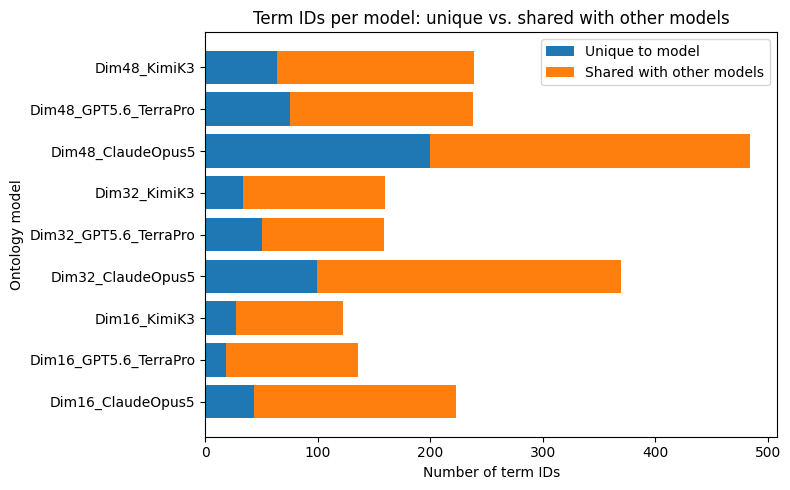

In [26]:
import seaborn as sns
import matplotlib.pyplot as plt

# Fraction of each model's unique term ids that do not appear in any other model's ontology
unique_counts = {}
shared_counts = {}
for key, ids in ontology_ids.items():
	own_ids = set(ids)
	other_ids = set().union(*(set(v) for k, v in ontology_ids.items() if k != key))
	unique_counts[key] = len(own_ids - other_ids)
	shared_counts[key] = len(own_ids) - unique_counts[key]

dim_order = ["Dim16", "Dim32", "Dim48"]
model_order = ["ClaudeOpus5", "GPT5.6_TerraPro", "KimiK3"]

def sort_key(key):
	dim, model = key.split("_", 1)
	return (dim_order.index(dim), model_order.index(model))

sorted_keys = sorted(ontology_ids, key=sort_key)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(sorted_keys, [unique_counts[k] for k in sorted_keys], label="Unique to model")
ax.barh(
	sorted_keys,
	[shared_counts[k] for k in sorted_keys],
	left=[unique_counts[k] for k in sorted_keys],
	label="Shared with other models",
)
ax.set_xlabel("Number of term IDs")
ax.set_ylabel("Ontology model")
ax.set_title("Term IDs per model: unique vs. shared with other models")
ax.legend()
plt.tight_layout()
plt.show()


## Core terms

Term IDs present in every model's ontology, i.e. the intersection across all
models regardless of latent size.

In [18]:
core_terms = set.intersection(*(set(ids) for ids in ontology_ids.values()))
print(f"Core terms shared across all models: {len(core_terms)}")


Core terms shared across all models: 5


## Pairwise term overlap

Direct term ID overlap between every pair of models, as raw shared-ID counts
and as the Jaccard index (intersection over union). Ordered by model family
then latent size; the diagonal (self-comparison) is excluded from the color
scale as it otherwise dominates the range.

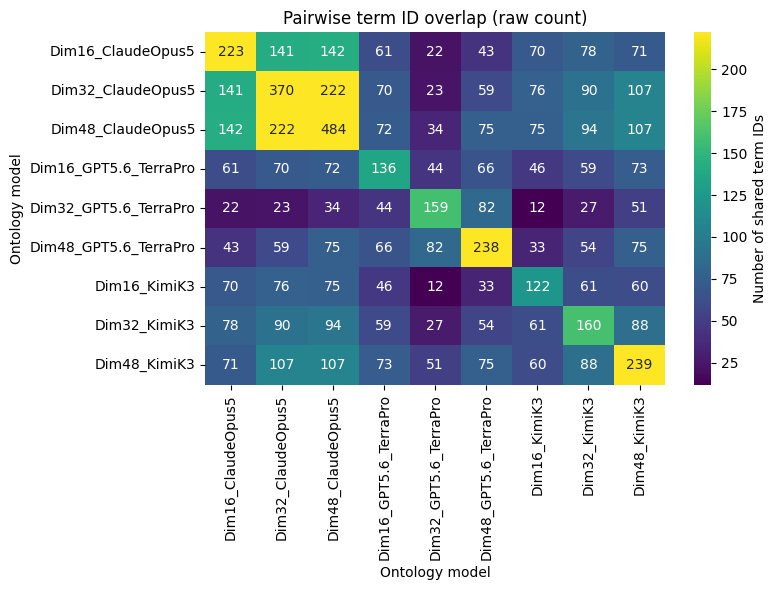

In [27]:
import numpy as np
import pandas as pd

# Order by model family first, then by dimension, unlike sorted_keys used in the bar plots
heatmap_keys = sorted(sorted_keys, key=lambda k: (model_order.index(k.split("_", 1)[1]), dim_order.index(k.split("_", 1)[0])))

overlap_matrix = pd.DataFrame(
	[[len(set(ontology_ids[key_a]) & set(ontology_ids[key_b])) for key_b in heatmap_keys] for key_a in heatmap_keys],
	index=heatmap_keys,
	columns=heatmap_keys,
)

# Scale colors by off-diagonal values only, since the diagonal (self-overlap) dominates the range
off_diag = overlap_matrix.values[~np.eye(len(overlap_matrix), dtype=bool)]

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(overlap_matrix, annot=True, fmt="d", cmap="viridis", vmin=off_diag.min(), vmax=off_diag.max(), ax=ax, cbar_kws={"label": "Number of shared term IDs"})
ax.set_xlabel("Ontology model")
ax.set_ylabel("Ontology model")
ax.set_title("Pairwise term ID overlap (raw count)")

plt.tight_layout()
plt.show()

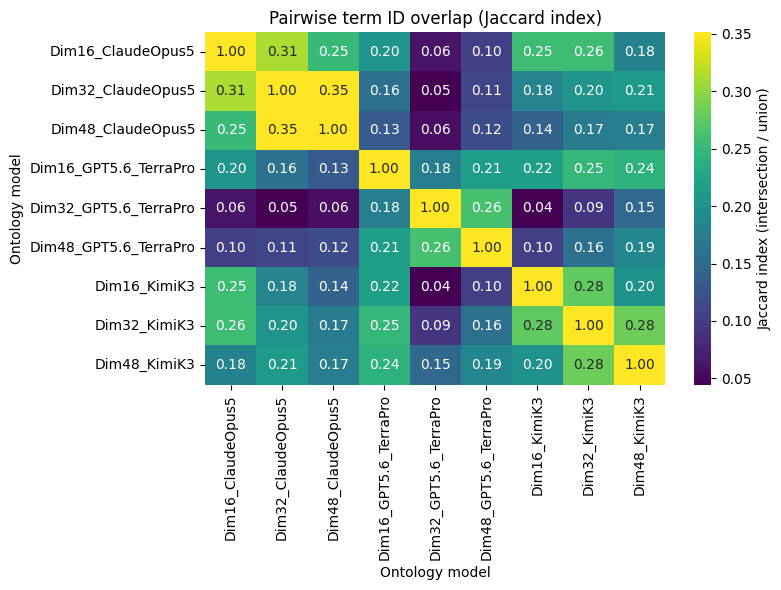

In [28]:
def jaccard(key_a, key_b):
	ids_a, ids_b = set(ontology_ids[key_a]), set(ontology_ids[key_b])
	return len(ids_a & ids_b) / len(ids_a | ids_b)

jaccard_matrix = pd.DataFrame(
	[[jaccard(key_a, key_b) for key_b in heatmap_keys] for key_a in heatmap_keys],
	index=heatmap_keys,
	columns=heatmap_keys,
)

# Scale colors by off-diagonal values only, since the diagonal (self-overlap = 1.0) dominates the range
off_diag = jaccard_matrix.values[~np.eye(len(jaccard_matrix), dtype=bool)]

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(jaccard_matrix, annot=True, fmt=".2f", cmap="viridis", vmin=off_diag.min(), vmax=off_diag.max(), ax=ax, cbar_kws={"label": "Jaccard index (intersection / union)"})
ax.set_xlabel("Ontology model")
ax.set_ylabel("Ontology model")
ax.set_title("Pairwise term ID overlap (Jaccard index)")

plt.tight_layout()
plt.show()

## Overlap using LLM-matched dimensions

Direct term ID overlap does not account for models describing the same biology
under different dimension names. Here we instead use the LLM-generated pairwise
dimension matches (`data/llm_ontologies/output_llms/stripped_comparisons/`) to
align dimensions before computing overlap, and separately quantify how many
dimensions could not be matched at all.

In [20]:
import glob as glob_module

comparison_dir = "../data/llm_ontologies/output_llms/stripped_comparisons/"

# Per-model, per-dimension term id sets (needed to score individual dimension matches)
dimension_term_ids = {}
for key, ontology in all_ontologies.items():
	dims = ontology[f"{key}_ontology"]
	dimension_term_ids[key] = {
		dim_name: {term["id"] for term in dims[dim_name]["ontology_terms"]}
		for dim_name in dims
	}

comparisons = {}
for filepath in glob_module.glob(os.path.join(comparison_dir, "*.json")):
	filename = os.path.basename(filepath)[:-len(".json")]
	key_a, key_b = filename.split("__vs__")
	with open(filepath, "r", encoding="utf-8") as f:
		comparisons[(key_a, key_b)] = json.load(f)

print(f"Loaded {len(comparisons)} pairwise dimension-match files")


Loaded 36 pairwise dimension-match files


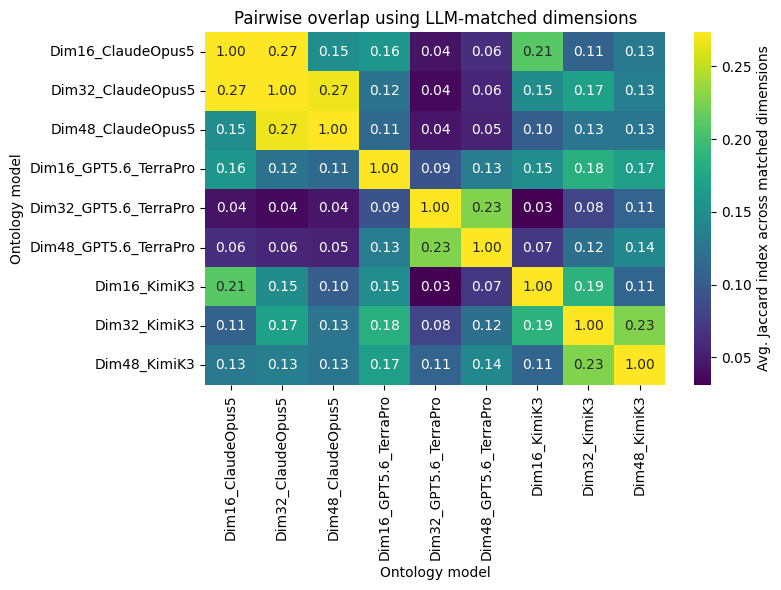

In [29]:
def matched_dimension_overlap(key_a, key_b, comparison):
	"""Average Jaccard overlap of term ids across all matched dimension pairs.

	A "match" is only considered when both sides list at least one dimension;
	matches can involve more than one dimension per side, in which case the
	term ids of all listed dimensions on that side are pooled first.
	"""
	scores = []
	for match in comparison["matches"]:
		dims_a = match["model1_dimensions"]
		dims_b = match["model2_dimensions"]
		if not dims_a or not dims_b:
			continue
		ids_a = set().union(*(dimension_term_ids[key_a][d] for d in dims_a))
		ids_b = set().union(*(dimension_term_ids[key_b][d] for d in dims_b))
		scores.append(len(ids_a & ids_b) / len(ids_a | ids_b))
	return sum(scores) / len(scores) if scores else 0.0

matched_overlap_matrix = pd.DataFrame(index=heatmap_keys, columns=heatmap_keys, dtype=float)
for key_a in heatmap_keys:
	for key_b in heatmap_keys:
		if key_a == key_b:
			matched_overlap_matrix.loc[key_a, key_b] = 1.0
			continue
		if (key_a, key_b) in comparisons:
			score = matched_dimension_overlap(key_a, key_b, comparisons[(key_a, key_b)])
		else:
			score = matched_dimension_overlap(key_b, key_a, comparisons[(key_b, key_a)])
		matched_overlap_matrix.loc[key_a, key_b] = score

# Scale colors by off-diagonal values only, since the diagonal (self-overlap = 1.0) dominates the range
off_diag = matched_overlap_matrix.values[~np.eye(len(matched_overlap_matrix), dtype=bool)]

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(matched_overlap_matrix, annot=True, fmt=".2f", cmap="viridis", vmin=off_diag.min(), vmax=off_diag.max(), ax=ax, cbar_kws={"label": "Avg. Jaccard index across matched dimensions"})
ax.set_xlabel("Ontology model")
ax.set_ylabel("Ontology model")
ax.set_title("Pairwise overlap using LLM-matched dimensions")

plt.tight_layout()
plt.show()

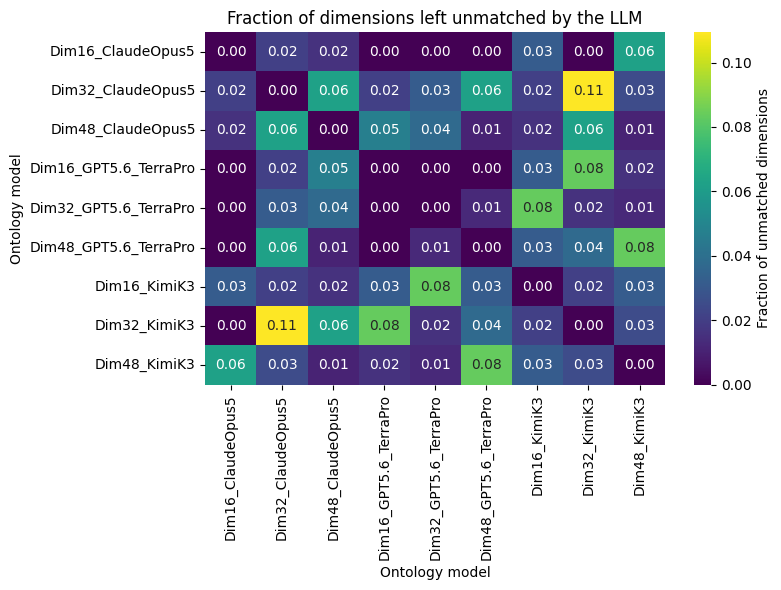

In [30]:
def unmatched_dimension_fraction(key_a, key_b, comparison):
	"""Fraction of dimensions (pooled across both models) left unmatched on the other side."""
	unmatched_a = sum(len(m["model1_dimensions"]) for m in comparison["matches"] if not m["model2_dimensions"])
	unmatched_b = sum(len(m["model2_dimensions"]) for m in comparison["matches"] if not m["model1_dimensions"])
	total_dims = len(dimension_term_ids[key_a]) + len(dimension_term_ids[key_b])
	return (unmatched_a + unmatched_b) / total_dims

unmatched_fraction_matrix = pd.DataFrame(index=heatmap_keys, columns=heatmap_keys, dtype=float)
for key_a in heatmap_keys:
	for key_b in heatmap_keys:
		if key_a == key_b:
			unmatched_fraction_matrix.loc[key_a, key_b] = 0.0
			continue
		if (key_a, key_b) in comparisons:
			fraction = unmatched_dimension_fraction(key_a, key_b, comparisons[(key_a, key_b)])
		else:
			fraction = unmatched_dimension_fraction(key_b, key_a, comparisons[(key_b, key_a)])
		unmatched_fraction_matrix.loc[key_a, key_b] = fraction

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(unmatched_fraction_matrix, annot=True, fmt=".2f", cmap="viridis", ax=ax, cbar_kws={"label": "Fraction of unmatched dimensions"})
ax.set_xlabel("Ontology model")
ax.set_ylabel("Ontology model")
ax.set_title("Fraction of dimensions left unmatched by the LLM")
plt.tight_layout()
plt.show()


## Gene-level ontology comparison

Beyond term IDs, each ontology term is annotated with the set of HUGO gene
symbols assigned to it (`*_ontology_with_genes.json`). We use this to compare
gene coverage across models and to quantify how densely genes are
cross-assigned to multiple ontology terms.

In [31]:
all_gene_ontologies = {}

for filepath in glob.glob(os.path.join(ontology_dir, "*_ontology_with_genes.json")):
	filename = os.path.basename(filepath)
	key = filename[:-len("_ontology_with_genes.json")]
	with open(filepath, "r", encoding="utf-8") as f:
		ontology = json.load(f)
	all_gene_ontologies[key] = ontology

print(f"Loaded {len(all_gene_ontologies)} gene-annotated ontologies: {list(all_gene_ontologies.keys())}")


Loaded 9 gene-annotated ontologies: ['Dim16_ClaudeOpus5', 'Dim32_KimiK3', 'Dim32_GPT5.6_TerraPro', 'Dim16_GPT5.6_TerraPro', 'Dim48_GPT5.6_TerraPro', 'Dim48_KimiK3', 'Dim48_ClaudeOpus5', 'Dim32_ClaudeOpus5', 'Dim16_KimiK3']


### Gene set extraction

For each model, collect the set of unique genes assigned to any ontology term
across all dimensions, together with the total number of (term, gene)
assignments (a gene is counted once for every term it is assigned to).

In [32]:
gene_sets = {}
gene_assignment_counts = {}
for key, ontology in all_gene_ontologies.items():
	terms = ontology[f"{key}_ontology"]
	assignments = [
		gene
		for dim_name in terms
		for term in terms[dim_name]["ontology_terms"]
		for gene in term["genes_hugo"]
	]
	gene_sets[key] = set(assignments)
	gene_assignment_counts[key] = len(assignments)

{key: {"unique_genes": len(gene_sets[key]), "gene_assignments": gene_assignment_counts[key]} for key in gene_sets}


{'Dim16_ClaudeOpus5': {'unique_genes': 11036, 'gene_assignments': 27763},
 'Dim32_KimiK3': {'unique_genes': 8446, 'gene_assignments': 18882},
 'Dim32_GPT5.6_TerraPro': {'unique_genes': 10015, 'gene_assignments': 16067},
 'Dim16_GPT5.6_TerraPro': {'unique_genes': 8423, 'gene_assignments': 14406},
 'Dim48_GPT5.6_TerraPro': {'unique_genes': 9884, 'gene_assignments': 18740},
 'Dim48_KimiK3': {'unique_genes': 9535, 'gene_assignments': 22334},
 'Dim48_ClaudeOpus5': {'unique_genes': 13422, 'gene_assignments': 39957},
 'Dim32_ClaudeOpus5': {'unique_genes': 11415, 'gene_assignments': 30411},
 'Dim16_KimiK3': {'unique_genes': 7144, 'gene_assignments': 15292}}

### Gene uniqueness across models

Analogous to the term ID uniqueness above: for each model, split its genes
into those unique to that model and those shared with at least one other
model.

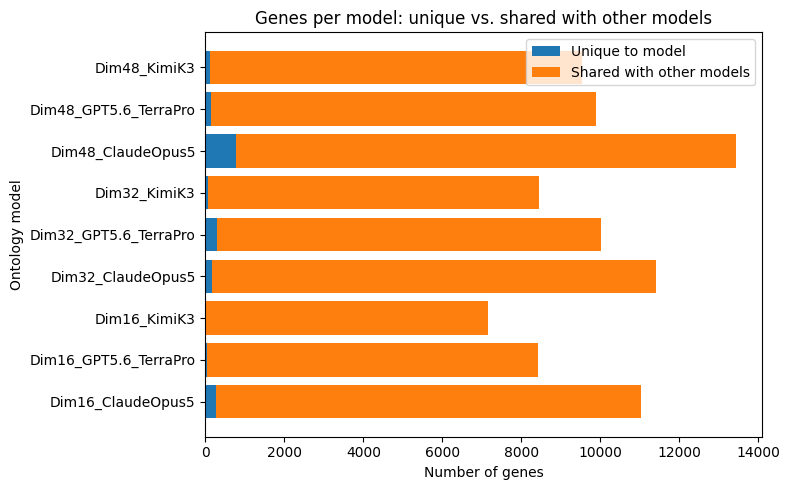

In [33]:
unique_gene_counts = {}
shared_gene_counts = {}
for key, genes in gene_sets.items():
	other_genes = set().union(*(g for k, g in gene_sets.items() if k != key))
	unique_gene_counts[key] = len(genes - other_genes)
	shared_gene_counts[key] = len(genes) - unique_gene_counts[key]

gene_sorted_keys = sorted(gene_sets, key=sort_key)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(gene_sorted_keys, [unique_gene_counts[k] for k in gene_sorted_keys], label="Unique to model")
ax.barh(
	gene_sorted_keys,
	[shared_gene_counts[k] for k in gene_sorted_keys],
	left=[unique_gene_counts[k] for k in gene_sorted_keys],
	label="Shared with other models",
)
ax.set_xlabel("Number of genes")
ax.set_ylabel("Ontology model")
ax.set_title("Genes per model: unique vs. shared with other models")
ax.legend()
plt.tight_layout()
plt.show()


### Ontology assignment level (sparseness)

Genes are frequently assigned to more than one ontology term. The ratio of
total (term, gene) assignments to unique genes gives an average assignment
level per gene: a value of 1 means the ontology is maximally sparse (each
gene tied to exactly one term), while higher values indicate denser, more
redundant term-gene assignment.

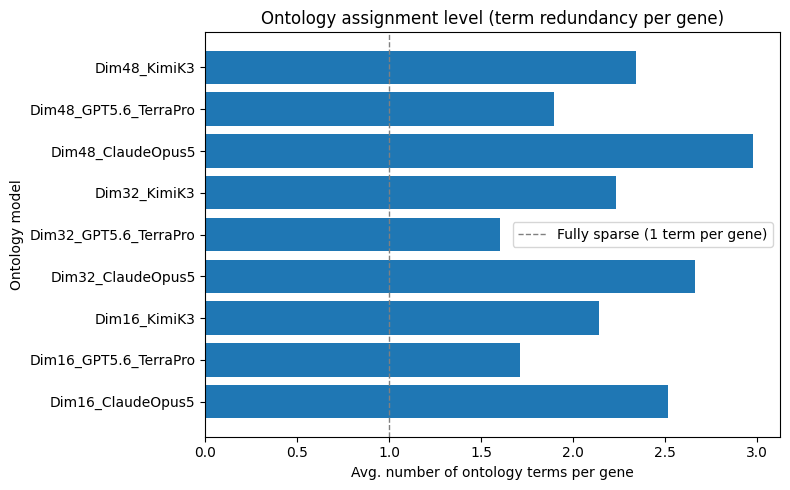

{'Dim16_ClaudeOpus5': 2.515675969554186,
 'Dim32_KimiK3': 2.235614492067251,
 'Dim32_GPT5.6_TerraPro': 1.6042935596605092,
 'Dim16_GPT5.6_TerraPro': 1.7103169891962484,
 'Dim48_GPT5.6_TerraPro': 1.895993524888709,
 'Dim48_KimiK3': 2.3423177766124805,
 'Dim48_ClaudeOpus5': 2.9769780956638354,
 'Dim32_ClaudeOpus5': 2.664126149802891,
 'Dim16_KimiK3': 2.1405375139977605}

In [34]:
assignment_level = {key: gene_assignment_counts[key] / len(gene_sets[key]) for key in gene_sets}

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(gene_sorted_keys, [assignment_level[k] for k in gene_sorted_keys])
ax.axvline(1.0, color="grey", linestyle="--", linewidth=1, label="Fully sparse (1 term per gene)")
ax.set_xlabel("Avg. number of ontology terms per gene")
ax.set_ylabel("Ontology model")
ax.set_title("Ontology assignment level (term redundancy per gene)")
ax.legend()
plt.tight_layout()
plt.show()

assignment_level
